# Objective 4: Out-of-time performance and investigation-budget evaluation

**Objective.** Assess out-of-sample and out-of-time performance with emphasis on how many enforcement-related (and restatement) cases a model surfaces when only the highest-risk **1%** or **5%** of firms can be investigated.

Uses the out-of-sample predictions saved by notebooks 02 (Compustat, AAER labels, 2003–2014) and 03 (XBRL, restatement labels, 2013–2024). Run those first.

Metrics: capture (share of all positives found within the budget), precision within the budget, lift over the base rate, firms examined per case found (1/precision), firm-cluster bootstrap intervals, frozen versus yearly retrained models, and the stability of fixed probability thresholds.

In [1]:
import sys, pathlib, warnings
sys.path.insert(0, str(pathlib.Path.cwd().parent / 'src'))
warnings.filterwarnings('ignore')
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from misstatement.config import *
from misstatement import data, metrics, models, plots
plots.style()
pd.set_option('display.width', 200); pd.set_option('display.max_columns', 40); pd.set_option('display.precision', 3)
from misstatement import fsds

In [2]:
pa = pd.read_parquet(CACHE / 'obj2_predictions_a.parquet'); pb = pd.read_parquet(CACHE / 'obj2_predictions_b.parquet')
bao_pred = pd.concat([pa, pb]); bao_pred['spec'] = bao_pred.model + ' | ' + bao_pred.fset
xb_pred = pd.read_parquet(CACHE / 'obj3_xbrl_restatement_predictions.parquet'); xb_pred['spec'] = xb_pred.model + ' | ' + xb_pred.fset
B_SPECS = ['LR | ratio', 'LR | raw', 'RUSBoost | raw', 'XGB | raw', 'GBM | raw', 'RF | raw', 'Size | raw']
X_SPECS = ['LR | xratio', 'LR | xall', 'RUSBoost | xall', 'XGB | xall', 'GBM | xall', 'Size | xraw']
b42 = bao_pred[(bao_pred.seed == 42) & bao_pred.spec.isin(B_SPECS)]
x42 = xb_pred[(xb_pred.seed == 42) & xb_pred.spec.isin(X_SPECS)]
print('Base rate, Compustat 2003-08:', round(b42[b42.fyear.isin(BAO_TEST_YEARS)].drop_duplicates(['fyear', 'firm']).y.mean(), 5))
print('Base rate, XBRL 2013-24:', round(x42.drop_duplicates(['fyear', 'firm']).y.mean(), 5))

Base rate, Compustat 2003-08: 0.00742
Base rate, XBRL 2013-24: 0.00935


## 1. Budget curves

In [3]:
KS = (0.005, 0.01, 0.02, 0.03, 0.05, 0.10, 0.20)
bc_b = metrics.budget_curve(b42[b42.fyear.isin(BAO_TEST_YEARS)], ['spec'], KS); bc_b['sample'] = 'Compustat/AAER 2003-08'
bc_l = metrics.budget_curve(b42[b42.fyear.isin(LATE_TEST_YEARS)], ['spec'], KS); bc_l['sample'] = 'Compustat/AAER 2009-14'
bc_x = metrics.budget_curve(x42, ['spec'], KS); bc_x['sample'] = 'XBRL/restatement 2013-24'
bc = pd.concat([bc_b, bc_l, bc_x]); bc['examined_per_case'] = 1 / bc.precision
bc.to_csv(TABLES / 'T20_obj4_budget_curves.csv', index=False)
bc[bc.k.isin([0.01, 0.05])].pivot_table(index=['sample', 'spec'], columns='k', values=['capture', 'precision', 'examined_per_case']).round(3)

capture        examined_per_case          precision       
k                                           0.01   0.05              0.01     0.05      0.01   0.05
sample                   spec                                                                      
Compustat/AAER 2003-08   GBM | raw         0.027  0.126            49.857   53.212     0.020  0.019
                         LR | ratio        0.027  0.107            49.857   62.714     0.020  0.016
                         LR | raw          0.027  0.134            49.857   50.171     0.020  0.020
                         RF | raw          0.023  0.146            58.167   46.211     0.017  0.022
                         RUSBoost | raw    0.034  0.126            38.778   53.212     0.026  0.019
                         Size | raw        0.004  0.069           349.000   97.556     0.003  0.010
                         XGB | raw         0.031  0.138            43.625   48.778     0.023  0.021
Compustat/AAER 2009-14   GBM | raw         0.036  0.134            82.000  110.067     0.012  0.009
                         LR | ratio        0.036  0.107            82.000  137.583     0.012  0.007
                         LR | raw          0.027  0.116           109.333  127.000     0.009  0.008
                         RF | raw          0.036  0.125            82.000  117.929     0.012  0.008
                         RUSBoost | raw    0.036  0.161            82.000   91.722     0.012  0.011
                         Size | raw        0.045  0.107            65.600  137.583     0.015  0.007
                         XGB | raw         0.045  0.125            65.600  117.929     0.015  0.008
XBRL/restatement 2013-24 GBM | xall        0.067  0.176            15.886   30.397     0.063  0.033
                         LR | xall         0.026  0.165            41.118   32.349     0.024  0.031
                         LR | xratio       0.030  0.130            34.950   41.000     0.029  0.024
                         RUSBoost | xall   0.029  0.144            36.789   37.116     0.027  0.027
                         Size | xraw       0.005  0.009           233.000  587.667     0.004  0.002
                         XGB | xall        0.047  0.170            22.548   31.482     0.044  0.032

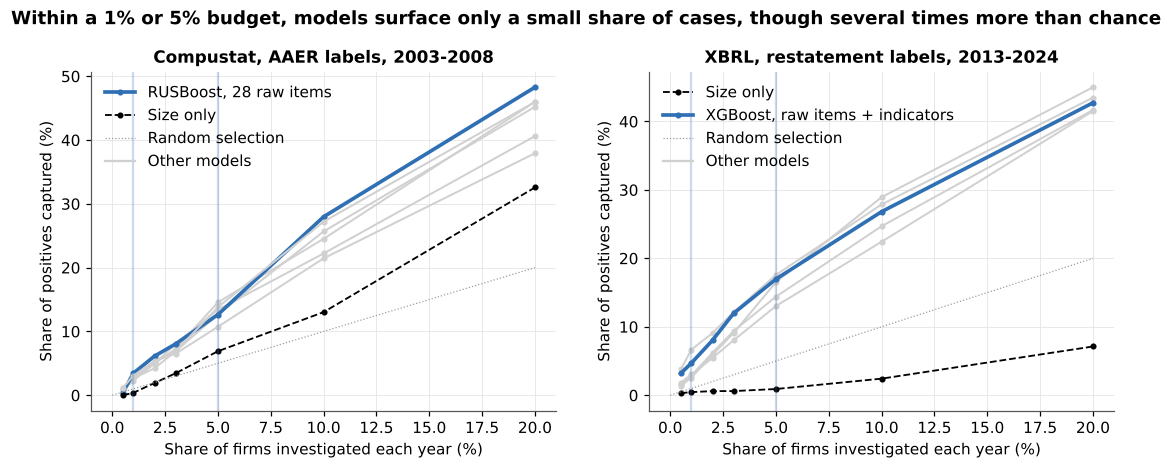

In [4]:
NICE = {'RUSBoost | raw': 'RUSBoost, 28 raw items', 'XGB | xall': 'XGBoost, raw items + indicators', 'Size | raw': 'Size only', 'Size | xraw': 'Size only'}
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=False)
for ax, (lab, df, hi) in zip(axes, [('Compustat, AAER labels, 2003-2008', bc_b, 'RUSBoost | raw'),
                                     ('XBRL, restatement labels, 2013-2024', bc_x, 'XGB | xall')]):
    for s, g in df.groupby('spec'):
        style = dict(color=plots.ACCENT, lw=2.4) if s == hi else dict(color='black', lw=1.2, ls='--') if s.startswith('Size') else dict(color=plots.LIGHT, lw=1.3)
        ax.plot(100 * g.k, 100 * g.capture, marker='o', ms=3, label=NICE.get(s, s) if (s == hi or s.startswith('Size')) else None, **style)
    ax.plot([0, 20], [0, 20], color=plots.GREY, lw=0.8, ls=':', label='Random selection')
    for k in (1, 5): ax.axvline(k, color=plots.ACCENT, alpha=0.25)
    ax.set_title(lab); ax.set_xlabel('Share of firms investigated each year (%)'); ax.set_ylabel('Share of positives captured (%)')
    ax.plot([], [], color=plots.LIGHT, label='Other models'); ax.legend(loc='upper left')
fig.suptitle('Within a 1% or 5% budget, models surface only a small share of cases, though several times more than chance', fontweight='bold', y=1.02)
plots.save(fig, 'F06_obj4_budget_curves'); plt.show()

## 2. Bootstrap intervals for capture within the 1% and 5% budgets

In [5]:
rows = []
for lab, df, yrs in (('Compustat 2003-08', b42, BAO_TEST_YEARS), ('XBRL 2013-24', x42, range(2013, 2025))):
    for s, g in df[df.fyear.isin(yrs)].groupby('spec'):
        for k in (0.01, 0.05):
            r = metrics.cluster_bootstrap(g.sort_values(['fyear', 'firm']), B=300, stat='capture', k=k)
            rows.append(dict(sample=lab, spec=s, k=k, capture=r['estimate'], lo=r['lo'], hi=r['hi']))
cap = pd.DataFrame(rows); cap.to_csv(TABLES / 'T21_obj4_capture_ci.csv', index=False)
cap.pivot_table(index=['sample', 'spec'], columns='k', values=['capture', 'lo', 'hi']).round(3)

capture            hi            lo       
k                                    0.01   0.05   0.01   0.05   0.01   0.05
sample            spec                                                      
Compustat 2003-08 GBM | raw         0.027  0.126  0.042  0.165  0.008  0.077
                  LR | ratio        0.027  0.107  0.057  0.156  0.011  0.064
                  LR | raw          0.027  0.134  0.058  0.195  0.012  0.091
                  RF | raw          0.023  0.146  0.047  0.207  0.005  0.098
                  RUSBoost | raw    0.034  0.126  0.063  0.176  0.008  0.078
                  Size | raw        0.004  0.069  0.016  0.111  0.000  0.035
                  XGB | raw         0.031  0.138  0.051  0.184  0.007  0.097
XBRL 2013-24      GBM | xall        0.067  0.176  0.084  0.204  0.047  0.144
                  LR | xall         0.026  0.165  0.037  0.192  0.015  0.138
                  LR | xratio       0.030  0.133  0.044  0.156  0.018  0.106
                  RUSBoost | xall   0.033  0.145  0.043  0.169  0.018  0.114
                  Size | xraw       0.005  0.009  0.009  0.020  0.000  0.003
                  XGB | xall        0.047  0.170  0.066  0.194  0.030  0.143

## 3. Frozen versus yearly retrained models
A model trained once and never updated is compared with the rolling (retrained every year) model.
* Compustat: frozen on 1991–2001 (serial AAERs continuing into any test year recoded), tested 2003–2014.
* XBRL: frozen on 2009–2014 with restatement labels public by the end of 2015, tested 2017–2024.

In [6]:
bao = data.load_bao()
def frozen_bao():
    tr = bao[bao.fyear <= 2001]; y = tr.misstate.values.copy()
    y[tr.p_aaer.isin(bao[(bao.fyear >= 2003) & (bao.misstate == 1)].p_aaer.dropna()).values] = 0
    out = []
    for m, f in (('LR', 'ratio'), ('RUSBoost', 'raw'), ('XGB', 'raw')):
        cols = data.RAT14 if f == 'ratio' else data.RAW28
        te = bao[bao.fyear.between(2003, 2014)]
        s, _ = models.fit_predict(m, cols, tr, y, te, log_lr=(f != 'ratio'))
        out.append(pd.DataFrame(dict(fyear=te.fyear.values, firm=te.gvkey.values, y=te.misstate.values, spec=f'{m} | {f}', score=s)))
    return pd.concat(out)
fz_b = models.cached(CACHE / 'obj4_frozen_bao.parquet', frozen_bao)

P = pd.read_parquet(DATA_PROCESSED / 'xbrl_panel.parquet'); R = pd.read_parquet(DATA_PROCESSED / 'xbrl_restatements.parquet')
P = P.merge(R[['cik', 'fyear', 'filed_a']], on=['cik', 'fyear'], how='left'); P['restated'] = P.filed_a.notna().astype(int)
X = P[(P.spac == 0)].reset_index(drop=True)
XFS = {'xratio': fsds.XRATIOS, 'xall': data.RAW27 + fsds.XRATIOS}
def frozen_xbrl():
    tr = X[X.fyear <= 2014]
    y = np.where(pd.to_datetime(tr.filed_a) <= pd.Timestamp('2015-12-31'), tr.restated, 0)
    te = X[X.fyear.between(2017, 2024)]; out = []
    for m, f in (('LR', 'xratio'), ('XGB', 'xall'), ('RUSBoost', 'xall')):
        s, _ = models.fit_predict(m, XFS[f], tr, y, te, log_lr=(f != 'xratio'))
        out.append(pd.DataFrame(dict(fyear=te.fyear.values, firm=te.cik.values, y=te.restated.values, spec=f'{m} | {f}', score=s)))
    return pd.concat(out)
fz_x = models.cached(CACHE / 'obj4_frozen_xbrl.parquet', frozen_xbrl)

def compare(fz, roll, windows):
    rows = []
    for spec in fz.spec.unique():
        for lab, yrs in windows:
            f = metrics.summarise(metrics.per_year(fz[fz.spec == spec], ['spec']), ['spec'], yrs).iloc[0]
            r = metrics.summarise(metrics.per_year(roll[roll.spec == spec], ['spec']), ['spec'], yrs).iloc[0]
            rows.append(dict(spec=spec, window=lab, auc_frozen=f.auc, auc_rolling=r.auc, hits5_frozen=f.hits5, hits5_rolling=r.hits5))
    return pd.DataFrame(rows)
cmp_b = compare(fz_b, bao_pred[bao_pred.seed == 42], [('2003-2008', BAO_TEST_YEARS), ('2009-2014', LATE_TEST_YEARS)])
cmp_x = compare(fz_x, xb_pred[xb_pred.seed == 42], [('2017-2020', range(2017, 2021)), ('2021-2024', range(2021, 2025))])
fr = pd.concat([cmp_b.assign(sample='Compustat'), cmp_x.assign(sample='XBRL')])
fr['auc_gain_from_retraining'] = fr.auc_rolling - fr.auc_frozen
fr.to_csv(TABLES / 'T22_obj4_frozen_vs_rolling.csv', index=False); fr.round(3)

,spec,window,auc_frozen,auc_rolling,hits5_frozen,hits5_rolling,sample,auc_gain_from_retraining
0,LR | ratio,2003-2008,0.688,0.691,27,28,Compustat,0.003
1,LR | ratio,2009-2014,0.749,0.749,18,12,Compustat,-0.000
2,RUSBoost | raw,2003-2008,0.711,0.716,34,33,Compustat,0.005
3,RUSBoost | raw,2009-2014,0.677,0.731,12,18,Compustat,0.054
4,XGB | raw,2003-2008,0.717,0.721,36,36,Compustat,0.004
5,XGB | raw,2009-2014,0.674,0.701,12,14,Compustat,0.027
0,LR | xratio,2017-2020,0.713,0.723,23,25,XBRL,0.010
1,LR | xratio,2021-2024,0.686,0.680,34,29,XBRL,-0.006
2,XGB | xall,2017-2020,0.686,0.706,45,39,XBRL,0.020
3,XGB | xall,2021-2024,0.656,0.705,28,39,XBRL,0.048


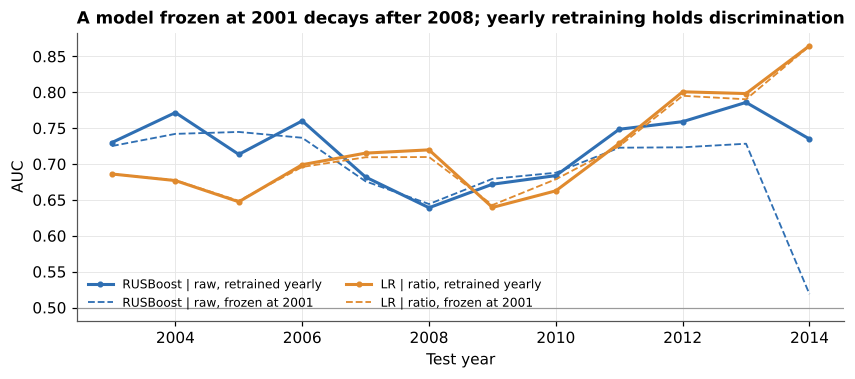

In [7]:
fy = metrics.per_year(fz_b, ['spec']); ry = metrics.per_year(bao_pred[bao_pred.seed == 42], ['spec'])
fig, ax = plt.subplots(figsize=(9, 3.4))
for spec, c in (('RUSBoost | raw', plots.ACCENT), ('LR | ratio', plots.SERIES[1])):
    ax.plot(ry[ry.spec == spec].fyear, ry[ry.spec == spec].auc, color=c, lw=2, marker='o', ms=3, label=f'{spec}, retrained yearly')
    ax.plot(fy[fy.spec == spec].fyear, fy[fy.spec == spec].auc, color=c, lw=1.2, ls='--', label=f'{spec}, frozen at 2001')
ax.axhline(0.5, color=plots.GREY, lw=0.8); ax.set_ylabel('AUC'); ax.set_xlabel('Test year'); plots.years(ax); ax.legend(ncol=2, loc='lower left', fontsize=8)
ax.set_title('A model frozen at 2001 decays after 2008; yearly retraining holds discrimination')
plots.save(fig, 'F07_obj4_frozen_vs_rolling'); plt.show()

## 4. Do fixed probability thresholds stay meaningful?
The probability at the 99th percentile of the first test year is held fixed and applied to later years. If the flagged share drifts away from 1%, a regulator using a fixed cut-off would see the workload change for reasons unrelated to misreporting.

In [8]:
rows = []
for lab, df, spec, first in (('Compustat, rolling', bao_pred[bao_pred.seed == 42], 'XGB | raw', 2003),
                             ('Compustat, frozen at 2001', fz_b, 'XGB | raw', 2003),
                             ('XBRL, rolling', xb_pred[xb_pred.seed == 42], 'XGB | xall', 2013),
                             ('XBRL, frozen at 2014', fz_x, 'XGB | xall', 2017)):
    g = df[df.spec == spec]
    thr = g[g.fyear == first].score.quantile(0.99)
    for y, gy in g.groupby('fyear'):
        rows.append(dict(model=lab, fyear=y, flagged_share=(gy.score > thr).mean(), exp_over_obs=gy.score.sum() / max(gy.y.sum(), 1)))
th = pd.DataFrame(rows); th.to_csv(TABLES / 'T23_obj4_threshold_drift.csv', index=False)
th.pivot(index='fyear', columns='model', values='flagged_share').round(4)

model,"Compustat, frozen at 2001","Compustat, rolling","XBRL, frozen at 2014","XBRL, rolling"
fyear,,,,
2003,0.010,0.010,NaN,NaN
2004,0.013,0.011,NaN,NaN
2005,0.015,0.016,NaN,NaN
2006,0.015,0.026,NaN,NaN
2007,0.018,0.025,NaN,NaN
2008,0.012,0.021,NaN,NaN
2009,0.011,0.015,NaN,NaN
2010,0.013,0.012,NaN,NaN
2011,0.014,0.012,NaN,NaN


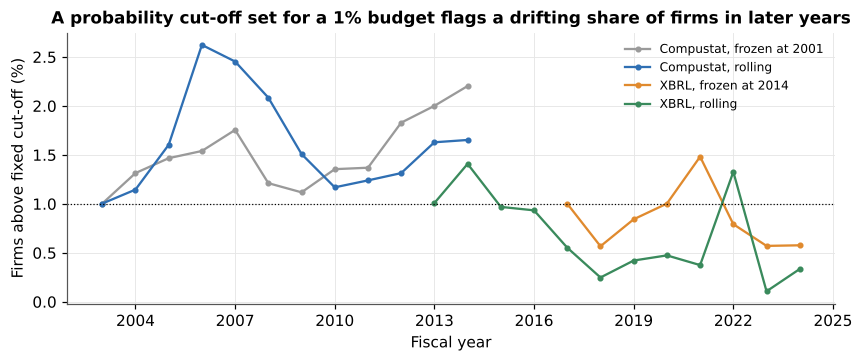

In [9]:
fig, ax = plt.subplots(figsize=(9, 3.2))
for (lab, g), c in zip(th.groupby('model'), [plots.GREY, plots.ACCENT, plots.SERIES[1], plots.SERIES[2]]):
    ax.plot(g.fyear, 100 * g.flagged_share, marker='o', ms=3, color=c, label=lab)
ax.axhline(1, color='black', lw=0.8, ls=':'); ax.set_ylabel('Firms above fixed cut-off (%)'); ax.set_xlabel('Fiscal year'); plots.years(ax)
ax.set_title('A probability cut-off set for a 1% budget flags a drifting share of firms in later years'); ax.legend(fontsize=8)
plots.save(fig, 'F08_obj4_threshold_drift'); plt.show()

## Findings for Objective 4

* At a 1% budget, the models capture only a few percent of AAER firm-years in 2003–2008 and a modest share of restatements in the XBRL sample; at 5% the capture rises to roughly a tenth to a fifth. Precision within the budget is low in absolute terms but several times the base rate (see tables).
* Bootstrap intervals for capture are wide because positives are rare; differences between learners within a budget are not distinguishable.
* Retraining matters: models frozen early lose discrimination over time, especially after 2008 in the Compustat data.
* Fixed probability thresholds drift; investigation budgets should be set as within-year percentiles of the risk score.